In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from scipy.stats import probplot, bootstrap
import ot
import jax
from jax import vmap
import jax.numpy as jnp
from jax.scipy.stats import norm

from sampling import conditional_sample, evaluate_MMD, gradient_flow, EBM_learner, create_parameters, optimise_KSD, evaluate_KSD

from typing import Any, Callable, Type, Optional
from typing_extensions import TypeAlias, Self
from divergences import mmd_fixed_target, mmd_dr_embedding, KSD, KSD_dr
from kernels import gaussian_kernel, IMQ_kernel
from embeddings import compute_EIF_a0, compute_plugin_a0, MMD, MMD_plugin, MMD_dr
from DGPs import DGP_univariate, DGP_multimodal, DGP_high_dim_X, DGP_high_dim_M, DGP_high_dim_MX, DGP_high_dim_Y
from KRR_utils import ard_median_heuristic, learn_hyperparams
from kernel_herding import kernel_herding_EIF, kernel_herding_plugin

%matplotlib inline
rng = np.random.default_rng(0)

In [21]:
def make_plots(Y_obs, Y_true, Y_EIF_herded, Y_plugin_herded):
    plt.figure(figsize=(8, 5))
    sns.histplot(np.array(Y_obs).ravel(), color="red", kde=True, stat="density", label="Logged", alpha=0.5)
    sns.histplot(np.array(Y_true).ravel(), color="blue", kde=True, stat="density", label="Truth", alpha=0.5)
    sns.histplot(
        Y_EIF_herded.ravel(),
        color="orange",
        kde=True,
        stat="density",
        label="Herded DR-CPME",
        alpha=0.5,
    )
    
    sns.histplot(
        Y_plugin_herded.ravel(),
        color="green",
        kde=True,
        stat="density",
        label="Herded PI-CPME",
        alpha=0.5,
    )
    plt.xlim([Y_true.mean()-4*Y_true.std(), Y_true.mean()+4*Y_true.std()])
    plt.xlabel("Y")
    plt.ylabel("Density")
    plt.legend()
    plt.title("Counterfactual Outcome Distribution via Kernel Herding")
    plt.tight_layout()
    plt.show()
    plt.close()

def make_joint_plots(Y_obs, Y_true, Y_EIF_herded, Y_plugin_herded):
    plt.figure(figsize=(8, 5))
    sns.jointplot(x=Y_obs[:,0],y=Y_obs[:,1],color="red",label="observed")
    sns.jointplot(x=Y_true[:,0],y=Y_true[:,1],color="blue",label="truth")
    sns.jointplot(x=Y_EIF_herded[:,0],y=Y_EIF_herded[:,1],color="orange",label="Herded DR-CKME")
    sns.jointplot(x=Y_plugin_herded[:,0],y=Y_plugin_herded[:,1],color="green",label="Herded PI-CKME")
    plt.legend()
    #plt.title("Counterfactual Outcome Distribution via Kernel Herding")
    plt.tight_layout()
    plt.show()
    plt.close()

In [3]:
n=4000
treatment=1
seed=1
dim=1

A,M,X,Y = DGP_multimodal(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

A,M,X,Y = DGP_multimodal(2*n,seed=seed,dim=dim)
A_tr=A[:n,:]
A_te=A[n:,:]
M_tr=M[:n,:]
M_te=M[n:,:]
X_tr=X[:n,:]
X_te=X[n:,:]
Y_tr=Y[:n,:]
Y_te=Y[n:,:]
A_truth,M_truth,X_truth,Y_truth = DGP_multimodal(n,seed=seed,dim=dim,gt=True,a0=treatment)

In [4]:
method='reggbm'

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,x_method=method,mx_method=method,params=params)
print('DR CKME: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,x_method=method,params=params)
print('PI CKME: ',jnp.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))

DR CKME:  0.071934946
PI CKME:  0.09535184


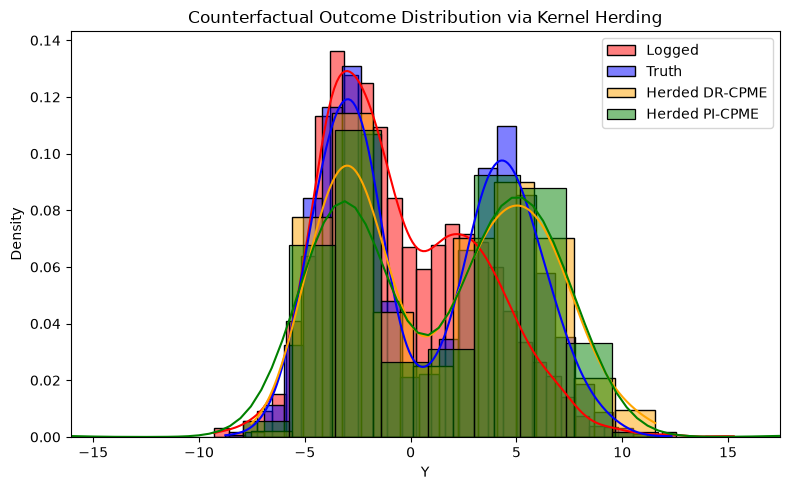

In [5]:

EIF_y_list=kernel_herding_EIF(np.array(Y_te),np.array(Y_tr),np.array(EIF),np.array(dr),500)
plugin_y_list=kernel_herding_plugin(np.array(Y_tr),np.array(plugin),500)

make_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [6]:
#MMD between estimated distributions and true distribution
print('PI CKME: ',jnp.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',jnp.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',jnp.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.09535184
DR CKME:  0.071934946
Herded PI:  0.095829315
Herded DR:  0.075710565


In [7]:
print('Herded PI: ',ot.sliced_wasserstein_distance(np.array(plugin_y_list.reshape(-1,1)),np.array(Y_truth)))
print('Herded DR: ',ot.sliced_wasserstein_distance(np.array(EIF_y_list.reshape(-1,1)),np.array(Y_truth)))

Herded PI:  3.1278085145766283
Herded DR:  0.8317597259181171


In [8]:
bandwidth=ard_median_heuristic(Y_tr)
rng_key = jax.random.key(0)
d=Y_tr.shape[1]

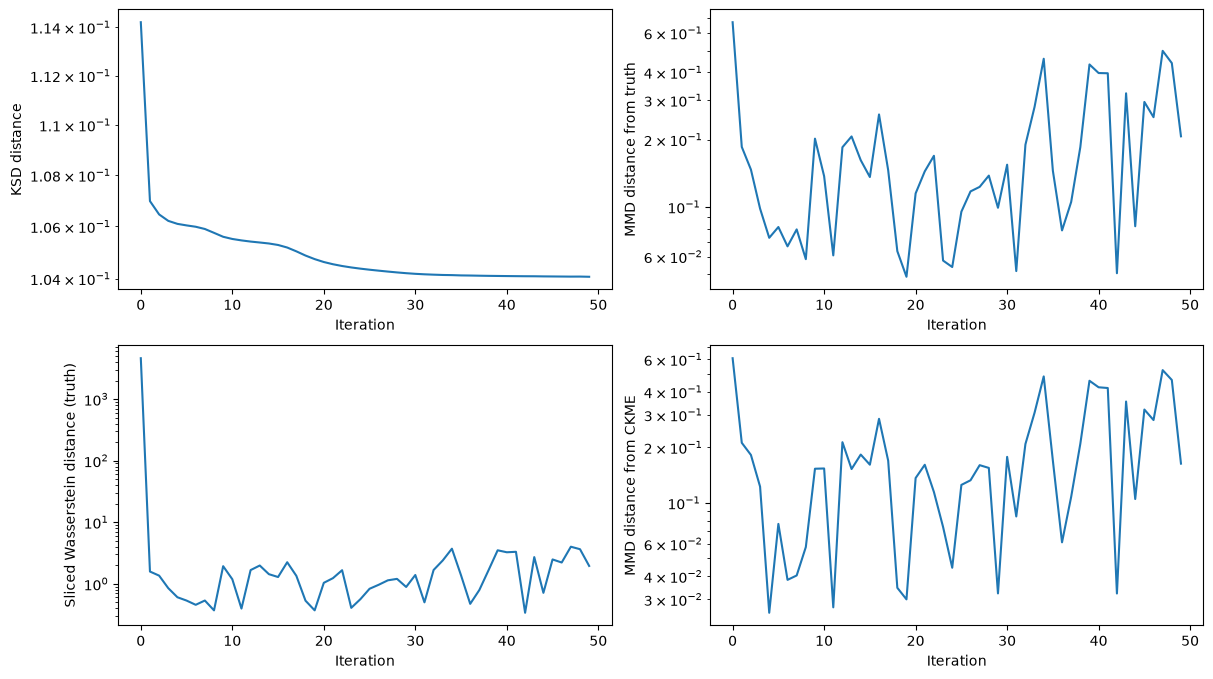

Initial KSD:  0.114204936
Final KSD:  0.10407086
Initial MMD (truth):  0.67003554
Final MMD (truth):  0.20688076
Initial sliced Wasserstein (truth):  4611.0503
Final sliced Wasserstein (truth):  1.950482


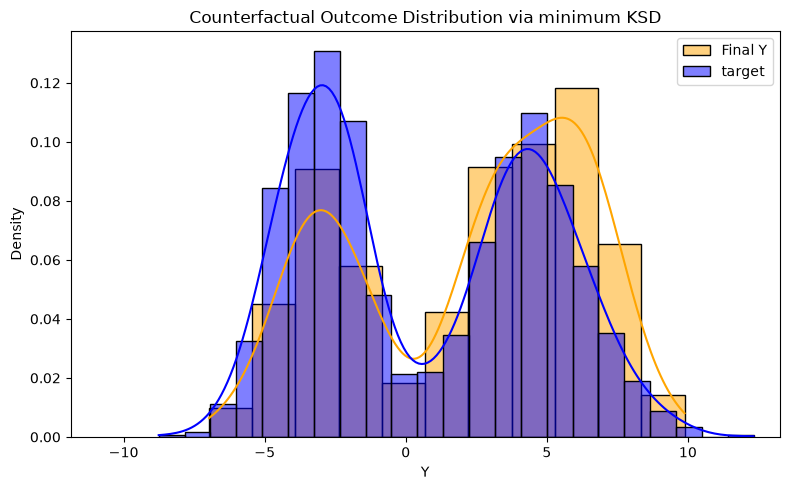

Initial MMD (CKME):  0.60854626
Final MMD (CKME):  0.16321819


In [9]:
k = EBM_learner()

ksd=KSD_dr(k, IMQ_kernel(bandwidth), dr, EIF)
ksd.pre_compute(Y_tr,Y_te)
key=jax.random.key(0)
params=create_parameters(key,Y_tr.shape[1])
param_estimates=optimise_KSD(ksd,rng_key,params,step_size=0.001,inject_noise_scale=100.,step_num=50000)
evaluate_KSD(ksd, param_estimates, 1000,rng_key, True, Y_truth)

sample


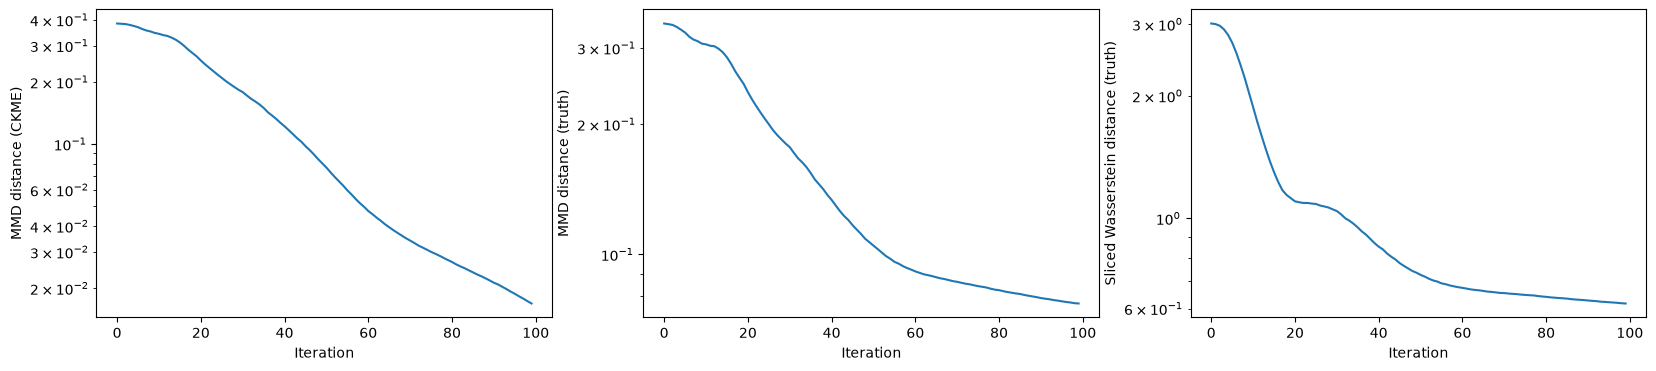

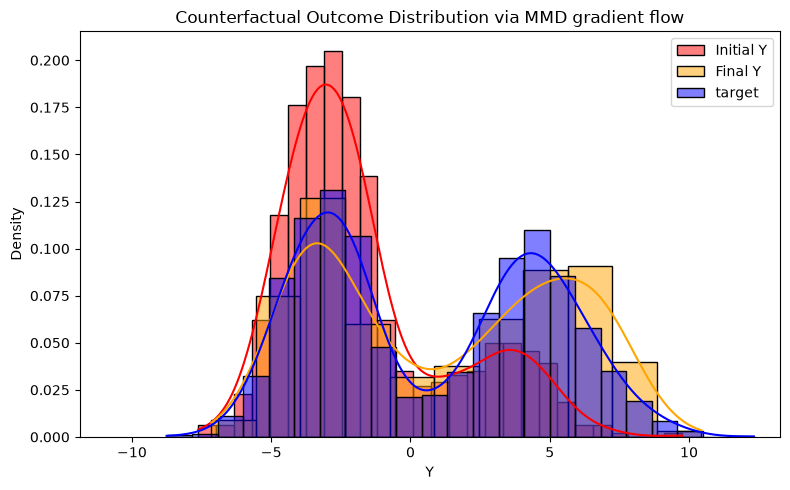

Initial MMD (truth):  0.34181005
Final MMD (truth):  0.07699028
Initial sliced Wasserstein (truth):  3.0106199
Final sliced Wasserstein (truth):  0.61731493
Initial MMD (CKME):  0.3840345
Final MMD (CKME):  0.0168572


In [10]:
#generate initial particle population
Y=conditional_sample(jnp.concatenate((Y_tr,Y_te),axis=0),jnp.concatenate((A_tr,A_te),axis=0),treatment=treatment)

#set kernel for MMD
kernel=gaussian_kernel(bandwidth)

divergence = mmd_dr_embedding(kernel, dr,EIF)
divergence.pre_compute(Y_tr,Y_te)

ret = gradient_flow(divergence, rng_key, Y,step_size=0.1,inject_noise_scale=1000.,step_num=100000)
rate = 1000
evaluate_MMD(kernel, ret, rate,target=Y_truth)

In [12]:
n=4000
treatment=0
seed=0
dim=3

A,M,X,Y = DGP_high_dim_Y(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

A,M,X,Y = DGP_high_dim_Y(2*n,seed=seed,dim=dim)
A_tr=A[:n,:]
A_te=A[n:,:]
M_tr=M[:n,:]
M_te=M[n:,:]
X_tr=X[:n,:]
X_te=X[n:,:]
Y_tr=Y[:n,:]
Y_te=Y[n:,:]
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_Y(n,seed=seed,dim=dim,gt=True,a0=treatment)

method='reggbm'

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,x_method=method,mx_method=method,params=params)
print('DR CKME: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,x_method=method,params=params)
print('PI CKME: ',jnp.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))

DR CKME:  0.088654816
PI CKME:  0.10012861


<Figure size 800x500 with 0 Axes>

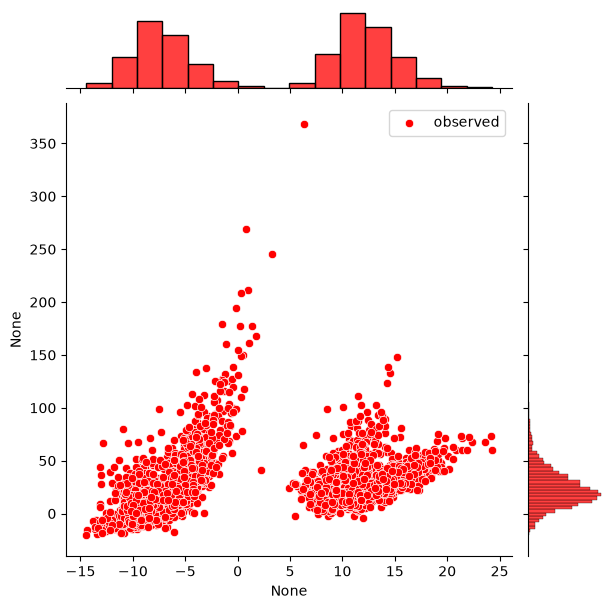

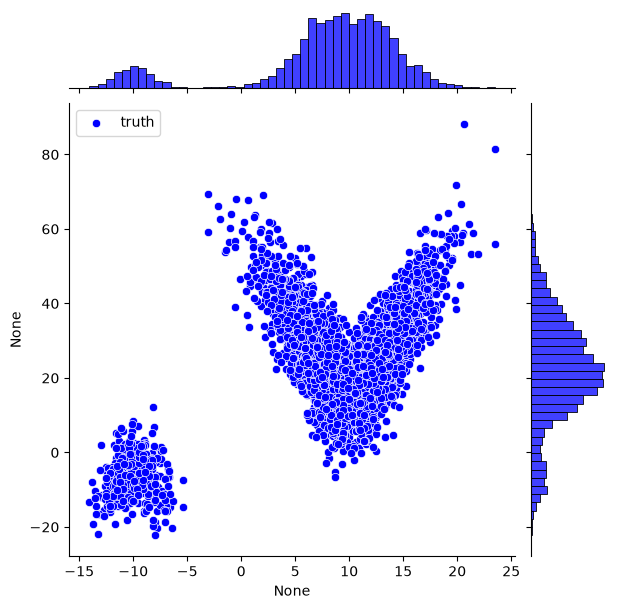

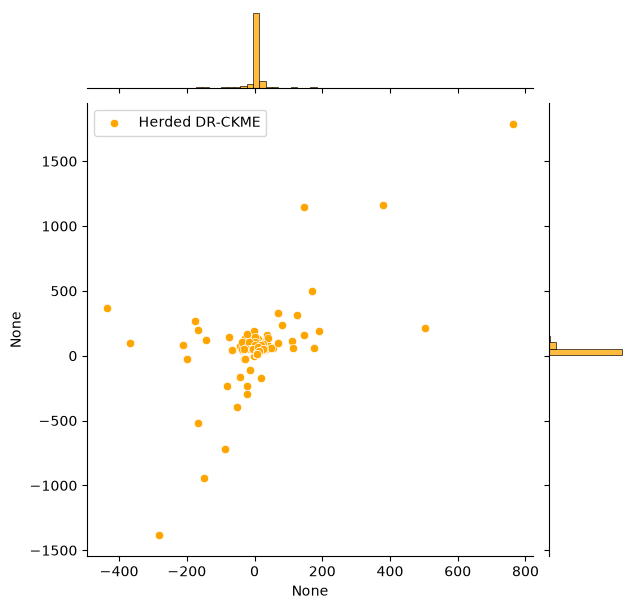

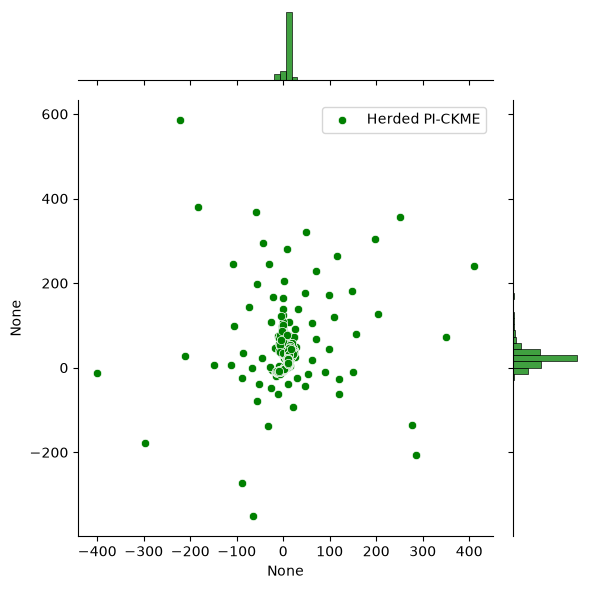

In [22]:
EIF_y_list=kernel_herding_EIF(np.array(Y_te),np.array(Y_tr),np.array(EIF),np.array(dr),1000)
plugin_y_list=kernel_herding_plugin(np.array(Y_tr),np.array(plugin),1000)

make_joint_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [23]:
print('PI CKME: ',jnp.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',jnp.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',jnp.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.10012861
DR CKME:  0.088654816
Herded PI:  0.41892183
Herded DR:  0.4886375


In [24]:
print('Herded PI: ',ot.sliced_wasserstein_distance(np.array(plugin_y_list),np.array(Y_truth)))
print('Herded DR: ',ot.sliced_wasserstein_distance(np.array(EIF_y_list),np.array(Y_truth)))

Herded PI:  35.08662390070922
Herded DR:  79.42973951897476


In [16]:
bandwidth=ard_median_heuristic(Y_tr)
rng_key = jax.random.key(0)
d=Y_tr.shape[1]

sample


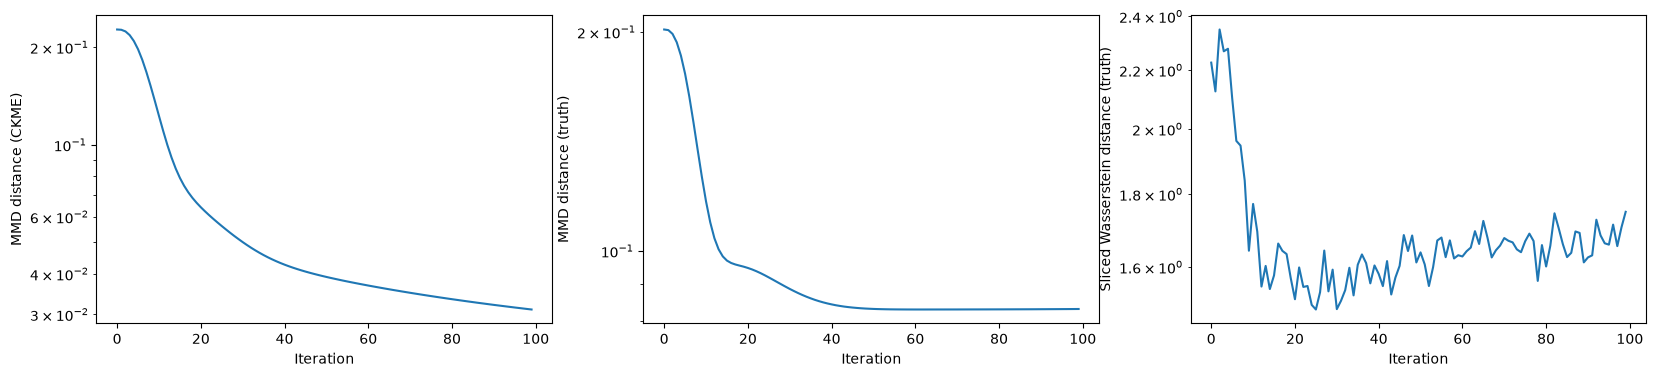

<Figure size 800x500 with 0 Axes>

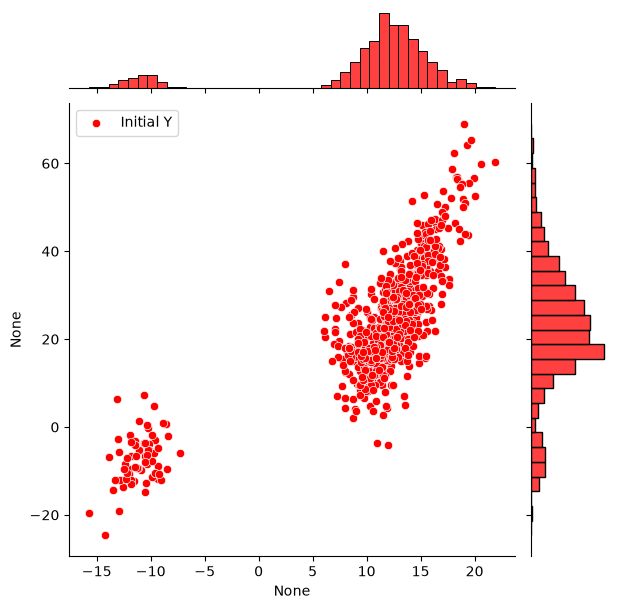

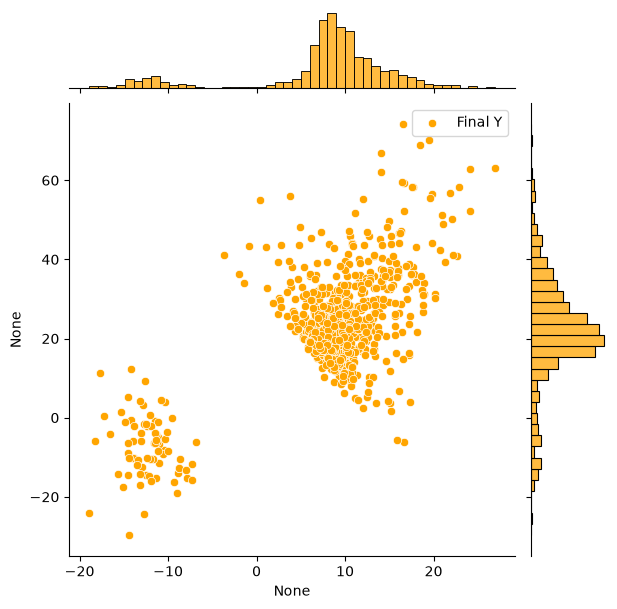

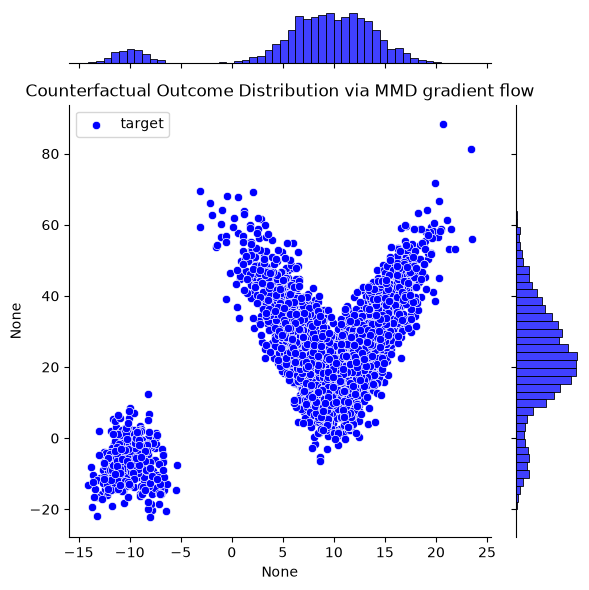

Initial MMD (truth):  0.2015691
Final MMD (truth):  0.08322904
Initial sliced Wasserstein (truth):  2.2266054
Final sliced Wasserstein (truth):  1.7492222
Initial MMD (CKME):  0.2268592
Final MMD (CKME):  0.03105724


In [17]:
#generate initial particle population
Y=conditional_sample(jnp.concatenate((Y_tr,Y_te),axis=0),jnp.concatenate((A_tr,A_te),axis=0),treatment=treatment)

#set kernel for MMD
kernel=gaussian_kernel(bandwidth)

divergence = mmd_dr_embedding(kernel, dr,EIF)
divergence.pre_compute(Y_tr,Y_te)

ret = gradient_flow(divergence, rng_key, Y,step_size=0.1,inject_noise_scale=1000.,step_num=100000)
rate = 1000
evaluate_MMD(kernel, ret, rate,target=Y_truth)

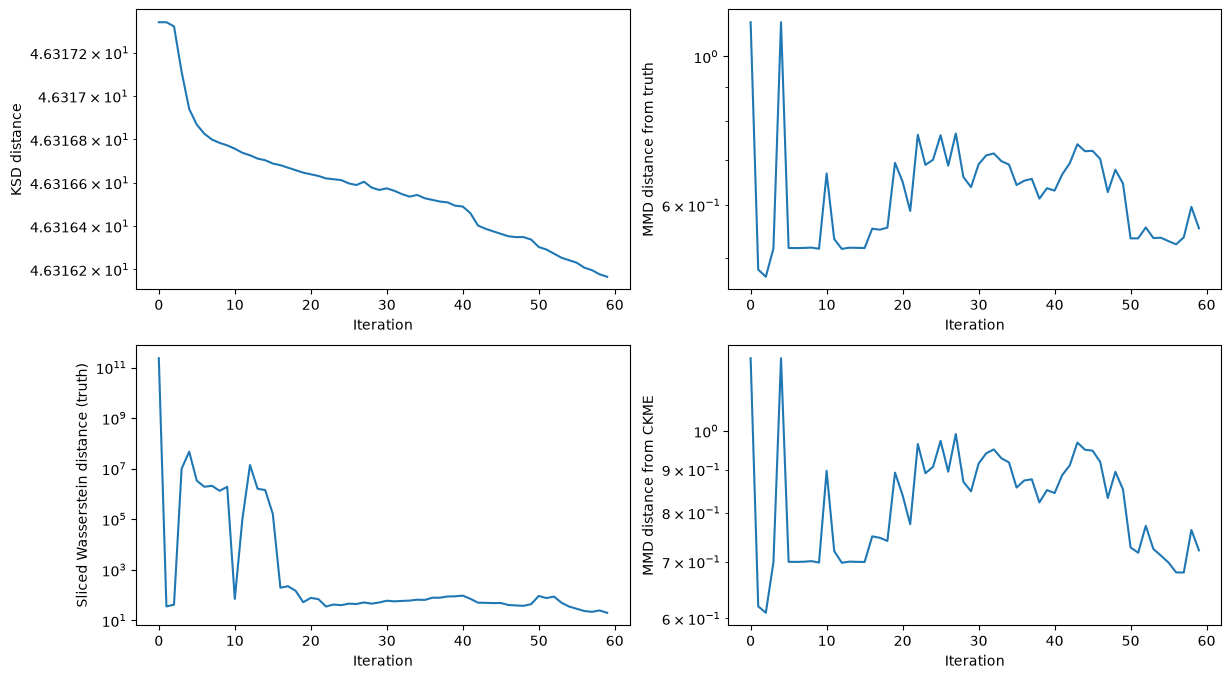

Initial KSD:  46.31734
Final KSD:  46.316166
Initial MMD (truth):  1.1249017
Final MMD (truth):  0.5541973
Initial sliced Wasserstein (truth):  2.3324834e+11
Final sliced Wasserstein (truth):  20.077568


<Figure size 800x500 with 0 Axes>

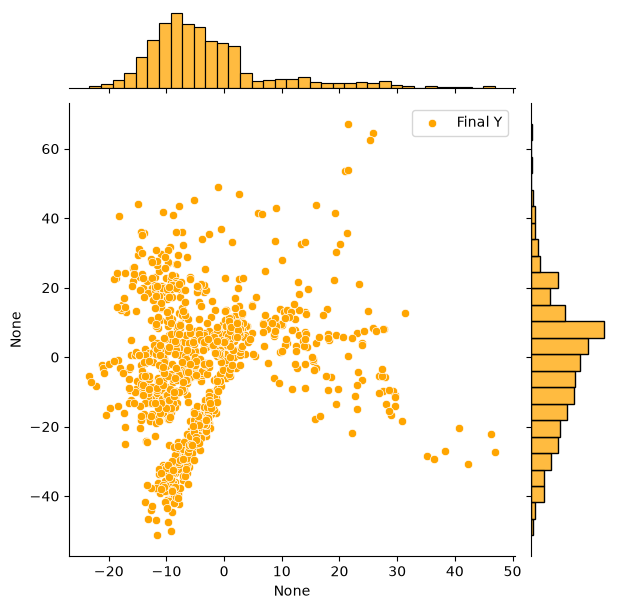

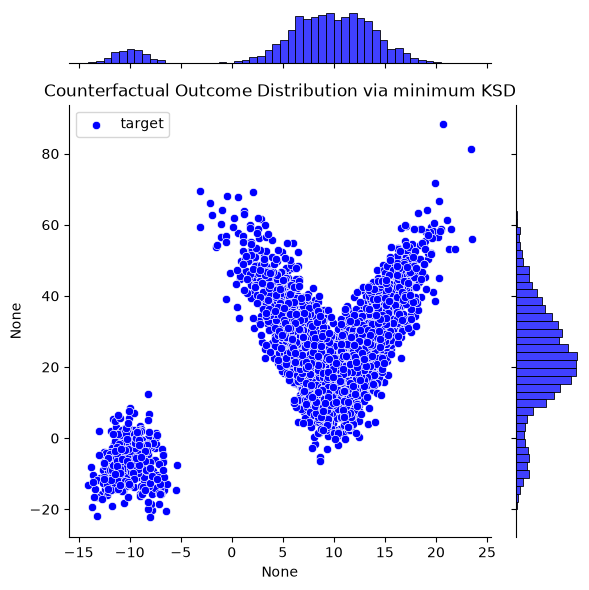

Initial MMD (CKME):  1.21896
Final MMD (CKME):  0.72219306


In [20]:
ebm = EBM_learner()

ksd=KSD_dr(ebm, IMQ_kernel(bandwidth), dr, EIF)
ksd.pre_compute(Y_tr,Y_te)
key=jax.random.key(0)
params=create_parameters(key,Y_tr.shape[1])
param_estimates=optimise_KSD(ksd,rng_key,params,step_size=0.001,inject_noise_scale=100.,step_num=60000)
evaluate_KSD(ksd, param_estimates, 1000,rng_key, True, Y_truth)